# Data Inspection

In [3]:
#1. Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


In [4]:
#2. Load the dataset

data = 'data/raw/raw_diabetic_data.csv'

df = pd.read_csv(data)


In [5]:
#3. Dataset dimensions

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Raw data has 101,766 rows and 50 columns.
# Encouner as hospital stay, not necessary unique patient


Rows: 101766
Columns: 50


In [6]:
#4. Inspect few rows

df.head()

# some attributes has data "?" --> to be categorize as Nan later on
# encounter_id and patient_nbr are unique identifiers - to be dropped as column later as it should not be used as predictors
# age as ordinal categorical


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [7]:
#5. Data types

df.info()

# admission_type_id, discharge_disposition_id, and admission_source_id are categorical variables represented as integers.
# convert into string type later
# medications as categorical
# numerical features: num_lab_procedures, num_procedures, num_medications,, number_outpatient, number_emergency, number_inpatient, num_diagnoses
# examine further the following: number_outpatient, number_emergency, number_inpatient
# num_lab_procedures vs. num_procedures


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [8]:
#6. Descriptive Statistics

df.describe(include='all')

# payer_code and medical_specialy most frequent value is "?"
# more than 50% of the data for number_outpatient, number_emergency, and number_inpatient = 0
# target variable = "readmitted" has no missing values
# Zero prior visits can be a valid history, so zero should not automatically be treated as missing.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,101766,101766,101766,101766,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,6,3,10,10,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),?,NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,98569,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
#7. Check for missing values

missing = df.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

# only max_glu_serum and A1Cresult has null values in the original dataset. but other variables has "?" in place of null.
# "?" to be handled later


max_glu_serum    96420
A1Cresult        84748
dtype: int64

In [10]:
#8. Check for Duplicate rows

print("Duplicate rows:", df.duplicated().sum()) 

# no duplicated rows
# NOTE: this does not rule out multiple different encounters belonging to the same patient


Duplicate rows: 0


In [11]:
#9. Check target variable ('readmitted') distribution

target_distribution = pd.DataFrame({
    'Count': df['readmitted'].value_counts(dropna=False),
    'Percentage': df['readmitted'].value_counts(normalize=True, dropna=False) * 100
}).round({'Percentage': 2})

target_distribution

# In the raw data, 11,357 encounters (11.16%) have a readmission within 30 days. The positive class is uncommon, making accuracy alone a poor evaluation measure.


,Count,Percentage
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


# Data Cleaning

In [12]:
# 10
# Objective of the analysis: Predicting whether a patient will be readmitted within 30 days or not
# As such, we need to check if the dataset contains unique patients or if there are multiple encounters for the same patient. 
# This is important because if a patient has multiple encounters, it may affect the independence of the observations and could introduce bias into the analysis.

# Check for unique patients and multiple encounters
# 16773 patients are non-unique or 23.45% of patients has multiple encounters

# Number of unique patients
unique_patients = df['patient_nbr'].nunique()

# Number of patients with multiple encounters
patient_counts = df['patient_nbr'].value_counts()

multi_encounter_patients = (patient_counts > 1).sum()

print("Total encounters:", len(df))
print("Unique patients:", unique_patients)
print("Patients with multiple encounters:", multi_encounter_patients)
print("Percentage of patients with multiple encounters:",
      round(multi_encounter_patients / unique_patients * 100, 2), "%")



Total encounters: 101766
Unique patients: 71518
Patients with multiple encounters: 16773
Percentage of patients with multiple encounters: 23.45 %


In [13]:
# 11
# Find patients with multiple encounters
patient_readmission = (
    df.groupby('patient_nbr')['readmitted']
      .nunique()
)

# Patients whose readmission status differs across encounters
patients_with_different_readmission = patient_readmission[
    patient_readmission > 1
]

print("Number of patients with different readmission values:",
      len(patients_with_different_readmission))

# Among patients with multiple hospital encounters (total of 16773), ~ 14,007 had different readmission outcomes across encounters. 
# This indicates that readmission status varies over time within the same patient and should therefore be treated as an encounter-level outcome.
# Option 1: filter the dataset to only include the first encounter for each patient, but this would reduce the dataset size and potentially remove valuable information about readmission patterns.
# Option 2: keep all encounters and treat readmission as an encounter-level outcome, train-test split to be done at the patient level to avoid data leakage


Number of patients with different readmission values: 14007


In [14]:
# 12
# Keep only the first encounter for each patient following the methodology of Strack et al. (2014)
# Simplify the modeling as the train-test split can be done without the risk of data leakage

# Sort by patient and encounter ID
df_sorted = df.sort_values(
    by=["patient_nbr", "encounter_id"]
)

# Keep the first encounter for each patient
df_first = df_sorted.drop_duplicates(
    subset="patient_nbr",
    keep="first"
).copy()

print("Rows before filtering:", len(df))
print("Rows after keeping first encounter:", len(df_first))
print("Unique patients:", df_first["patient_nbr"].nunique())


Rows before filtering: 101766
Rows after keeping first encounter: 71518
Unique patients: 71518


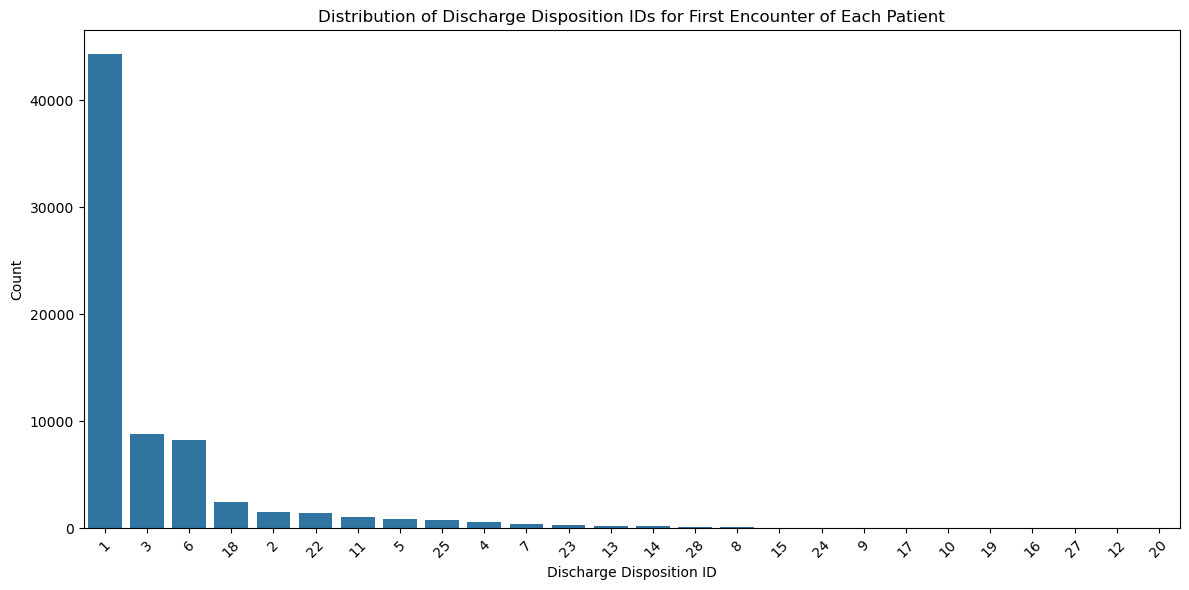

In [15]:
# 13
# View the distribution of discharge disposition IDs for the first encounter of each patient.
# To know the condition of a patient when they were discharged. 

# ==== Comments ====
# Majority was discharged to home, followed by discharged to nursing facility
# Some records showed death or at hospice, in which the expected readmission outcome would be "NO" since the patient is deceased or at hospice care.

df_first["discharge_disposition_id"].value_counts().sort_index()

# create a bar plot for the distribution of discharge disposition IDs for the first encounter of each patient
plt.figure(figsize=(12, 6))
sns.countplot(data=df_first, x='discharge_disposition_id', order=df_first['discharge_disposition_id'].value_counts().index)
plt.title('Distribution of Discharge Disposition IDs for First Encounter of Each Patient')
plt.xlabel('Discharge Disposition ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


This plot describes where patients went after discharge. Discharge information is suitable for prediction at discharge, but would not be available for an admission-time prediction.

In [16]:
# 14
# Count and percentage of readmission status by discharge disposition. See if there is a relationship between discharge disposition and readmission status.
# Interested in the following discharge disposition IDs:
# 11 = Expired
# 19 = Hospice
# 20 = Hospice
# 21 = Expired
# As expected, death related discharge codes has 100% readmission status as "No" (not readmitted).
# While majority who are at hospice care are also not readmitted, there are some who are readmitted. 
# This may be due to the fact that some patients may be discharged to hospice care for end-of-life care
# but may still require hospitalization for symptom management or other medical needs.
# To avoid bias, I will exclude these discharge disposition IDs from the analysis.

discharge_summary = (
    df_first.groupby('discharge_disposition_id')['readmitted']
      .value_counts()
      .unstack(fill_value=0)
)

# Calculate row percentages
discharge_pct = (
    discharge_summary
    .div(discharge_summary.sum(axis=1), axis=0)
    .mul(100)
)

# Combine count and percentage into one value
discharge_summary_combined = discharge_summary.astype(str) + " (" + \
    discharge_pct.round(2).astype(str) + "%)"

discharge_summary_combined

# Death and hospice-related discharge codes

death_hospice_codes = [11, 13, 14, 19, 20, 21]

discharge_summary_combined.loc[
    discharge_summary_combined.index.isin(death_hospice_codes)
]

# The table compares outcomes within excluded disposition categories. 
# Some hospice-related categories still contain readmissions; their exclusion defines the intended cohort rather than proving readmission is impossible.


readmitted,<30,>30,NO
discharge_disposition_id,,,
11,0 (0.0%),0 (0.0%),1077 (100.0%)
13,5 (2.06%),16 (6.58%),222 (91.36%)
14,11 (5.05%),2 (0.92%),205 (94.04%)
19,0 (0.0%),0 (0.0%),6 (100.0%)
20,0 (0.0%),0 (0.0%),1 (100.0%)


In [17]:
# 15
# Remove encounters with death/hospice-related discharge dispositions
# Following the methodology of Strack et al. (2014)

excluded_dispositions = [11, 13, 14, 19, 20, 21]

df_final = df_first[
    ~df_first["discharge_disposition_id"].isin(excluded_dispositions)
].copy()

print("Rows before removing excluded dispositions:", len(df_first))
print("Rows after removing excluded dispositions:", len(df_final))
print("Unique patients:", df_final["patient_nbr"].nunique())


# The specified discharge exclusions reduce the cohort from 71,518 to 69,973 patients.


Rows before removing excluded dispositions: 71518
Rows after removing excluded dispositions: 69973
Unique patients: 69973


In [18]:
# 16

# Compare target distribution: Raw vs. Final data

# --- RESULTS -----
# The target distribution remains broadly consistent between the raw and final datasets
# although preprocessing increased the proportion of non-readmitted encounters from 53.91% to 59.27% 
# and reduced the proportion of encounters readmitted within 30 days from 11.16% to 8.97%.
# Need to be cautious of class imbalance

df_raw = df.copy()

raw_dist = (
    df_raw["readmitted"]
    .value_counts(normalize=False)
    .to_frame("Raw Count")
)

final_dist = (
    df_final["readmitted"]
    .value_counts(normalize=False)
    .to_frame("Final Count")
)

# Combine counts
target_comparison = raw_dist.join(final_dist, how="outer").fillna(0)

# Add percentages
target_comparison["Raw %"] = (
    target_comparison["Raw Count"] / len(df_raw) * 100
)

target_comparison["Final %"] = (
    target_comparison["Final Count"] / len(df_final) * 100
)

# Format
target_comparison["Raw %"] = target_comparison["Raw %"].round(2)
target_comparison["Final %"] = target_comparison["Final %"].round(2)

target_comparison


,Raw Count,Final Count,Raw %,Final %
readmitted,,,,
<30,11357,6277,11.16,8.97
>30,35545,22222,34.93,31.76
NO,54864,41474,53.91,59.27


In [19]:
# 18
# Summary of '?' values in each column
# '?' is used as a special missing-value indicator in the original dataset.

# === Result ====
# 96% of the weight values are missing, which is a significant proportion. 
# This may be due to the fact that weight is not always recorded in medical records, or it may be missing for other reasons. 
# The other columns with missing values are also important to consider, as they may impact the analysis and modeling process.

missing_summary = pd.DataFrame({
    'Missing Count': (df_final == '?').sum(),
    'Missing %': (df_final == '?').mean() * 100
})

# Keep only columns that contain '?'
missing_summary = (
    missing_summary[missing_summary['Missing Count'] > 0]
    .sort_values('Missing %', ascending=False)
)

# Round percentage
missing_summary['Missing %'] = missing_summary['Missing %'].round(2)

missing_summary


,Missing Count,Missing %
weight,67185,96.02
medical_specialty,33639,48.07
payer_code,30415,43.47
race,1918,2.74
diag_3,1224,1.75
diag_2,293,0.42
diag_1,10,0.01


In [20]:
# 19
# Check unique values and missing values for selected categorical variables

for col in ['race', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']:
    print(f"\n{'='*50}")
    print(f"{col}")
    print(f"Unique values: {df_final[col].nunique(dropna=True)}")
    print(f"Missing values ('?'): {(df_final[col] == '?').sum()}")
    print("\nMost common values:")
    print(df_final[col].value_counts(dropna=False).head(10))



race
Unique values: 6
Missing values ('?'): 1918

Most common values:
race
Caucasian          52292
AfricanAmerican    12625
?                   1918
Hispanic            1500
Other               1150
Asian                488
Name: count, dtype: int64

payer_code
Unique values: 18
Missing values ('?'): 30415

Most common values:
payer_code
?     30415
MC    19782
HM     3984
BC     3397
SP     3303
MD     2165
CP     1939
UN     1855
CM     1295
OG      647
Name: count, dtype: int64

medical_specialty
Unique values: 71
Missing values ('?'): 33639

Most common values:
medical_specialty
?                             33639
InternalMedicine              10641
Family/GeneralPractice         4978
Emergency/Trauma               4393
Cardiology                     4207
Surgery-General                2205
Orthopedics                    1128
Orthopedics-Reconstructive     1041
Radiologist                     821
Nephrology                      797
Name: count, dtype: int64

diag_1
Unique values:

In [21]:
# 20
# Replace '?' with np.nan for easier handling of missing values in the analysis

df_final.replace('?', np.nan, inplace=True)

# Show the first few rows of the cleaned dataset
df_final.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
4267,24437208,135,Caucasian,Female,[50-60),NaN,2,1,1,8,...,No,Steady,No,No,No,No,No,Ch,Yes,<30
5827,29758806,378,Caucasian,Female,[50-60),NaN,3,1,1,2,...,No,No,No,No,No,No,No,No,No,NO
67608,189899286,729,Caucasian,Female,[80-90),NaN,1,3,7,4,...,No,No,No,No,No,No,No,No,Yes,NO
17494,64331490,774,Caucasian,Female,[80-90),NaN,1,1,7,3,...,No,No,No,No,No,No,No,Ch,Yes,NO
2270,14824206,927,AfricanAmerican,Female,[30-40),NaN,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,NO


In [22]:
# 21
# Check the distribution of categorical variables in the cleaned dataset

categorical_cols = [
    "race",
    "gender",
    "payer_code",
    "medical_specialty",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
    "change",
    "diabetesMed",
    "readmitted"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_final[col].value_counts(dropna=False))


# ==== Comments =====
# Gender has 3 unknown/invalid values - consider dropping or imputing these values
# medical specialty has 71 distinct categories, some categories have very few observations, 48% missing values
# "?" replaced with NaN


# almost constant medication columns that can be dropped:
# -- examide and citoglipton have only one unique value
# -- <3 not "no": acetohexamide, troglizatone, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone





race:
race
Caucasian          52292
AfricanAmerican    12625
NaN                 1918
Hispanic            1500
Other               1150
Asian                488
Name: count, dtype: int64

gender:
gender
Female             37229
Male               32741
Unknown/Invalid        3
Name: count, dtype: int64

payer_code:
payer_code
NaN    30415
MC     19782
HM      3984
BC      3397
SP      3303
MD      2165
CP      1939
UN      1855
CM      1295
OG       647
PO       457
DM       372
WC       117
CH       113
OT        62
SI        37
MP        32
FR         1
Name: count, dtype: int64

medical_specialty:
medical_specialty
NaN                       33639
InternalMedicine          10641
Family/GeneralPractice     4978
Emergency/Trauma           4393
Cardiology                 4207
                          ...  
SportsMedicine                1
Dermatology                   1
Perinatology                  1
Neurophysiology               1
Resident                      1
Name: count, Length: 

In [23]:
# 22
# Final check of the dataset after preprocessing


print("Shape:", df_final.shape)
print("\n--- Columns and types ---")
print(df_final.dtypes.to_string())

print("\n--- Missing values (only columns with any) ---")
miss = df_final.isna().sum()
print(miss[miss > 0].to_string() if (miss > 0).any() else "None")

print("\n--- Duplicates ---")
print("Duplicate rows:", df_final.duplicated().sum())
if "encounter_id" in df_final.columns:
    print("Duplicate encounter_id:", df_final["encounter_id"].duplicated().sum())
if "patient_nbr" in df_final.columns:
    print("Unique patients:", df_final["patient_nbr"].nunique(),
          "| Repeat-patient rows:", df_final["patient_nbr"].duplicated().sum())

print("\n--- Target ---")
if "readmitted" in df_final.columns:
    print(df_final["readmitted"].value_counts(dropna=False).to_string())

print("\n--- Diagnosis columns ---")
for c in [c for c in df_final.columns if c.startswith("diag")]:
    print(f"\n{c} (unique = {df_final[c].nunique()}):")
    print(df_final[c].value_counts().head(12).to_string())

print("\n--- Discharge disposition values present ---")
if "discharge_disposition_id" in df_final.columns:
    print(sorted(df_final["discharge_disposition_id"].unique()))

print("\n--- Constant columns ---")
print([c for c in df_final.columns if df_final[c].nunique() <= 1])


# This audit checks types, missingness, repeat patients, outcomes, and constants before final preparation. 
# The intermediate cohort has 69,973 rows; remaining missing values still require explicit handling.


Shape: (69973, 50)

--- Columns and types ---
encounter_id                int64
patient_nbr                 int64
race                          str
gender                        str
age                           str
weight                        str
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
time_in_hospital            int64
payer_code                    str
medical_specialty             str
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                        str
diag_2                        str
diag_3                        str
number_diagnoses            int64
max_glu_serum                 str
A1Cresult                     str
metformin                     str
repaglinide                   str
nateglinide                   str
chlorpropamide                str
gl

In [24]:
# Export cleaned data

Path("data/processed").mkdir(parents=True, exist_ok=True)
output_path = Path("data/processed/diabetic_clean.csv")
df_final.to_csv(output_path, index=False)
print("Saved to:", output_path)


Saved to: data/processed/diabetic_clean.csv


# Final Data cleaning

In [25]:
# Load preprocessed data

preprocessed_data = 'data/processed/diabetic_clean.csv'

df_preprocessed = pd.read_csv(preprocessed_data)


In [26]:
# Removes invalid-gender rows, fixes splits, learns medication exclusions from training only, and prepares the target. 
# The cohort now has 69,970 patients and 6,277 positives; the original answer column is removed.

#  ---------------------------------------------------------------
# Step 1: Drop columns that will not be used
# ---------------------------------------------------------------
# Fix cohort eligibility before splitting; keep identity separately from predictors.
df_preprocessed = df_preprocessed[df_preprocessed["gender"] != "Unknown/Invalid"].copy()
patient_identity = df_preprocessed[["patient_nbr", "encounter_id"]].copy()
assert patient_identity["patient_nbr"].is_unique

from sklearn.model_selection import train_test_split
split_target = (df_preprocessed["readmitted"] == "<30").astype(int)
temp_indices, test_indices = train_test_split(
    df_preprocessed.index, test_size=0.15, stratify=split_target, random_state=42)
train_indices, val_indices = train_test_split(
    temp_indices, test_size=0.15 / 0.85,
    stratify=split_target.loc[temp_indices], random_state=42)
split_indices = {"train": train_indices, "val": val_indices, "test": test_indices}

# Learn the medication exclusion rule using training patients only.
medication_columns = df_preprocessed.columns[
    df_preprocessed.columns.get_loc("metformin"):
    df_preprocessed.columns.get_loc("change")].tolist()
training_medications = df_preprocessed.loc[train_indices, medication_columns]
medication_audit = pd.DataFrame({
    "Medication": medication_columns,
    "Training non-No count": training_medications.ne("No").sum().values,
})
medication_audit["Excluded"] = medication_audit["Training non-No count"] < 3
rare_medications = medication_audit.loc[medication_audit.Excluded, "Medication"].tolist()
DROP_COLS = ["weight", "encounter_id", "patient_nbr"] + rare_medications
df_preprocessed = df_preprocessed.drop(columns=DROP_COLS)
Path("reports/final_audit").mkdir(parents=True, exist_ok=True)
medication_audit.to_csv("reports/final_audit/training_medication_selection.csv", index=False)
print("Training-only excluded medications:", rare_medications)
print("Rows after cohort eligibility:", len(df_preprocessed))

# ---------------------------------------------------------------
# Step 3: Fill missing values with fixed labels
# (no values are calculated from other rows, so there is no leakage)
# ---------------------------------------------------------------
for col in ["max_glu_serum", "A1Cresult"]:
    df_preprocessed[col] = df_preprocessed[col].fillna("Not_tested")    # blank = test was not performed

for col in ["race", "payer_code", "medical_specialty"]:
    df_preprocessed[col] = df_preprocessed[col].fillna("Unknown")

# ---------------------------------------------------------------
# Step 4: Binary target (1 = readmitted within 30 days, 0 = otherwise)
# ---------------------------------------------------------------
df_preprocessed["readmit_30"] = (df_preprocessed["readmitted"] == "<30").astype(int)
df_preprocessed = df_preprocessed.drop(columns=["readmitted"])          # original column contains the answer

# ---------------------------------------------------------------
# Checks
# ---------------------------------------------------------------
print("\nShape:", df_preprocessed.shape)
print("\nTarget counts:\n", df_preprocessed["readmit_30"].value_counts().to_string())
print("Positive rate (%):", round(df_preprocessed["readmit_30"].mean() * 100, 2))

missing = df_preprocessed.isna().sum()
print("\nRemaining missing:",
      missing[missing > 0].to_dict() if (missing > 0).any() else "None")

print("\nLab test coverage:")
print(df_preprocessed["max_glu_serum"].value_counts().to_string())
print(df_preprocessed["A1Cresult"].value_counts().to_string())


Training-only excluded medications: ['acetohexamide', 'examide', 'citoglipton', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Rows after cohort eligibility: 69970

Shape: (69970, 41)

Target counts:
 readmit_30
0    63693
1     6277
Positive rate (%): 8.97

Remaining missing: {'diag_1': 10, 'diag_2': 293, 'diag_3': 1224}

Lab test coverage:
max_glu_serum
Not_tested    66622
Norm           1700
>200            936
>300            712
A1Cresult
Not_tested    57125
>8             6239
Norm           3741
>7             2865


In [27]:
# Maps diagnosis codes into broad groups, with diabetes checked before the wider endocrine range. 
# Unknown diagnoses remain explicit categories. 
# Fixed mapping rules do not learn information from validation/test rows

# ---------------------------------------------------------------
# Diagnosis mapping: ICD-9 codes -> broad disease groups
# Diabetes (250.xx) is its own group
# ---------------------------------------------------------------

# (lowest code, highest code, group name) -- bounds are inclusive.
# The FIRST match wins, so Diabetes must stay above the Endocrine range.
ICD9_GROUPS = [
    (1,   139,    "Infectious and Parasitic"),
    (140, 239,    "Neoplasms"),
    (250, 250.99, "Diabetes"),
    (240, 289,    "Endocrine, Nutritional, Metabolic, and Blood"),
    (290, 319,    "Mental Disorders"),
    (320, 389,    "Nervous System and Sense Organs"),
    (390, 459,    "Circulatory"),
    (460, 519,    "Respiratory"),
    (520, 579,    "Digestive"),
    (580, 629,    "Genitourinary"),
    (630, 679,    "Pregnancy, Childbirth, and Puerperium"),
    (680, 709,    "Skin and Subcutaneous Tissue"),
    (710, 739,    "Musculoskeletal"),
    (740, 759,    "Congenital Anomalies"),
    (760, 779,    "Perinatal Conditions"),
    (780, 799,    "Symptoms, Signs, and Ill-Defined Conditions"),
    (800, 999,    "Injury and Poisoning"),
]

# Supplementary codes start with a letter instead of a number
LETTER_CODE_GROUPS = {
    "V": "Supplementary Factors",
    "E": "External Causes of Injury",
}


def group_icd9(code):
    """Convert an ICD-9-CM diagnosis code into a broad disease group."""
    if pd.isna(code):
        return "Unknown"
    code = str(code).strip()
    if code == "":
        return "Unknown"

    if code[0] in LETTER_CODE_GROUPS:
        return LETTER_CODE_GROUPS[code[0]]

    try:
        code_num = float(code)
    except ValueError:
        return "Other/Unknown"

    for low, high, group in ICD9_GROUPS:
        if low <= code_num <= high:
            return group
    return "Other/Unknown"


# Create the grouped columns, then drop the raw codes
for col in ["diag_1", "diag_2", "diag_3"]:
    df_preprocessed[col + "_group"] = df_preprocessed[col].apply(group_icd9)

# ---------------------------------------------------------------
# Checks
# ---------------------------------------------------------------
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    print(f"\n{col}")
    print(df_preprocessed[col].value_counts().to_string())

print("\nShape:", df_preprocessed.shape)

missing = df_preprocessed.isna().sum()
missing = missing[missing > 0]

if missing.empty:
    print("Remaining missing: None")
else:
    missing_summary = pd.DataFrame({
        "Missing Count": missing,
        "Missing %": (missing / len(df_preprocessed) * 100).round(2),
    }).sort_values("Missing Count", ascending=False)
    print("Remaining missing:")
    print(missing_summary.to_string())



diag_1_group
diag_1_group
Circulatory                                     21315
Respiratory                                      6446
Digestive                                        6325
Diabetes                                         5748
Symptoms, Signs, and Ill-Defined Conditions      5503
Injury and Poisoning                             4692
Musculoskeletal                                  4064
Genitourinary                                    3414
Neoplasms                                        2538
Endocrine, Nutritional, Metabolic, and Blood     2501
Skin and Subcutaneous Tissue                     1780
Infectious and Parasitic                         1685
Mental Disorders                                 1545
Supplementary Factors                             918
Nervous System and Sense Organs                   858
Pregnancy, Childbirth, and Puerperium             586
Congenital Anomalies                               41
Unknown                                            10
E

In [28]:
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    counts = df_preprocessed[col].value_counts()
    percent = (counts / len(df_preprocessed) * 100).round(2)
    print(f"\n{col}")
    print(pd.DataFrame({"Count": counts, "Percent": percent}).to_string())

    # NOTE: Counts and percentages describe how common each diagnosis group is. Frequency alone does not establish which group is most predictive of readmission.



diag_1_group
                                              Count  Percent
diag_1_group                                                
Circulatory                                   21315    30.46
Respiratory                                    6446     9.21
Digestive                                      6325     9.04
Diabetes                                       5748     8.21
Symptoms, Signs, and Ill-Defined Conditions    5503     7.86
Injury and Poisoning                           4692     6.71
Musculoskeletal                                4064     5.81
Genitourinary                                  3414     4.88
Neoplasms                                      2538     3.63
Endocrine, Nutritional, Metabolic, and Blood   2501     3.57
Skin and Subcutaneous Tissue                   1780     2.54
Infectious and Parasitic                       1685     2.41
Mental Disorders                               1545     2.21
Supplementary Factors                           918     1.31
Nervous Sy

In [29]:
# Check distribution of diagnosis codes and their corresponding groups

df_preprocessed[["diag_1", "diag_1_group", "diag_2", "diag_2_group", "diag_3", "diag_3_group"]].drop_duplicates().sort_values("diag_1").head(30)


,diag_1,diag_1_group,diag_2,diag_2_group,diag_3,diag_3_group
68909,10,Infectious and Parasitic,585,Genitourinary,14,Infectious and Parasitic
8586,11,Infectious and Parasitic,714,Musculoskeletal,250,Diabetes
9157,11,Infectious and Parasitic,250.01,Diabetes,401,Circulatory
36210,11,Infectious and Parasitic,403,Circulatory,585,Genitourinary
38740,11,Infectious and Parasitic,401,Circulatory,250,Diabetes
40142,11,Infectious and Parasitic,496,Respiratory,250.02,Diabetes
44455,11,Infectious and Parasitic,250.02,Diabetes,V15,Supplementary Factors
47031,11,Infectious and Parasitic,428,Circulatory,780,"Symptoms, Signs, and Ill-Defined Conditions"
60893,11,Infectious and Parasitic,518,Respiratory,348,Nervous System and Sense Organs
24527,110,Infectious and Parasitic,250.7,Diabetes,785,"Symptoms, Signs, and Ill-Defined Conditions"


In [30]:
# Drop diag_1, diag_2, and diag_3
# Removes the three original diagnosis columns after grouping. This reduces categorical complexity while retaining the broader clinical categories.

df_preprocessed = df_preprocessed.drop(columns=['diag_1', 'diag_2', 'diag_3'])


In [31]:
df_preprocessed.info()

# The final modeling table has 69,970 rows and 40 non-null columns. 
# No nulls remain because missing categories are explicit labels; this does not mean every clinical measurement was collected.


<class 'pandas.DataFrame'>
Index: 69970 entries, 0 to 69972
Data columns (total 41 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   race                      69970 non-null  str  
 1   gender                    69970 non-null  str  
 2   age                       69970 non-null  str  
 3   admission_type_id         69970 non-null  int64
 4   discharge_disposition_id  69970 non-null  int64
 5   admission_source_id       69970 non-null  int64
 6   time_in_hospital          69970 non-null  int64
 7   payer_code                69970 non-null  str  
 8   medical_specialty         69970 non-null  str  
 9   num_lab_procedures        69970 non-null  int64
 10  num_procedures            69970 non-null  int64
 11  num_medications           69970 non-null  int64
 12  number_outpatient         69970 non-null  int64
 13  number_emergency          69970 non-null  int64
 14  number_inpatient          69970 non-null  int64
 15  n

In [32]:
# 5. Save (same path style your notebook already uses)
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)
df_preprocessed.to_csv("data/processed/diabetic_cleaned_final.csv", index=False)
print("Saved:", Path("data/processed/diabetic_cleaned_final.csv"))


Saved: data/processed/diabetic_cleaned_final.csv


**Explanation / key finding:** Exports df_preprocessed to diabetic_cleaned_final.csv, matching the filename printed and loaded by the split step. This resolves the earlier wrong-DataFrame and mismatched-path issue.

# Data Split

In [33]:
# Imports stratified splitting. Stratification keeps the positive-class share similar across training, validation, and test data.

from sklearn.model_selection import train_test_split


In [34]:
# Test, train, validation
# The split yields 48,978 training rows, 10,496 validation rows, and 10,496 test rows, each about 8.97% positive. 
# The fixed seed makes the split repeatable; models should be selected using training/validation data before final test reporting.

SEED = 42

df_final = pd.read_csv("data/processed/diabetic_cleaned_final.csv")
print("Loaded:", df_final.shape)

X = df_final.drop(columns="readmit_30")
y = df_final["readmit_30"]

# Reuse the exact split membership established before medication selection.
positions = {name: patient_identity.index.get_indexer(indices)
             for name, indices in split_indices.items()}
X_train, y_train = X.iloc[positions["train"]], y.iloc[positions["train"]]
X_val, y_val = X.iloc[positions["val"]], y.iloc[positions["val"]]
X_test, y_test = X.iloc[positions["test"]], y.iloc[positions["test"]]

# Check sizes and positive rates
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:11} rows: {len(labels):6}  positives: {labels.sum():5}  "
          f"positive rate: {labels.mean() * 100:.2f}%")

# Save
out = Path("data/processed")
for name, Xs, ys in [("train", X_train, y_train),
                     ("val",   X_val,   y_val),
                     ("test",  X_test,  y_test)]:
    Xs.assign(readmit_30=ys).to_csv(out / f"{name}.csv", index=False)
print("Saved train.csv, val.csv, test.csv")

# Manifest row order matches each saved split; identifiers never enter model inputs.
manifest_parts = []
for name, indices in split_indices.items():
    identity = patient_identity.loc[indices].reset_index(drop=True)
    identity.insert(0, "Row", range(len(identity)))
    identity.insert(0, "Split", name)
    manifest_parts.append(identity)
manifest = pd.concat(manifest_parts, ignore_index=True)
assert manifest.patient_nbr.is_unique
assert manifest.encounter_id.is_unique
assert len(manifest) == len(df_final)
manifest.to_csv(out / "split_patient_manifest.csv", index=False)
print("Saved exact patient/encounter split manifest; all patients are unique.")


Loaded: (69970, 41)
Train       rows:  48978  positives:  4393  positive rate: 8.97%
Validation  rows:  10496  positives:   942  positive rate: 8.97%
Test        rows:  10496  positives:   942  positive rate: 8.97%
Saved train.csv, val.csv, test.csv
Saved exact patient/encounter split manifest; all patients are unique.
